# Formality under a GSM8K constraint

The optimization package (`steerability.optimization`) searches a space of steering pipelines for the one with the largest gain in a behavior score, subject to a limit on the accuracy that the model may lose on a capability benchmark. The selected pipelines are then certified on held-out items, i.e., items that the search never reads. The [optimization tutorial](../../../../tutorials/optimize_steering_pipelines.md) describes the package in detail.

This notebook runs one such study. We steer `Qwen/Qwen2.5-0.5B-Instruct` toward a formal register with a [CAA](https://arxiv.org/abs/2312.06681) vector and allow its accuracy on [GSM8K](https://huggingface.co/datasets/openai/gsm8k) to fall by at most five points. The study searches over the layer and the multiplier of the vector.

The study reads its scores from a recorded grid rather than from a loaded model. In a preparation phase, every (layer, multiplier) setting of the vector was evaluated once on a fixed set of items of each benchmark, and the study is replayed on those scores. The replay runs on a CPU. It also gives the true loss and gain of every setting, which we use to check the decisions of the study.

### Runtime estimate

> **Estimated time:** <10 minutes  
> **Device:** CPU

The recorded scores come from a preparation phase of about 21 GPU-hours on NVIDIA A100 GPUs (80GB VRAM), which the Preparation section describes. The notebook downloads them from the Hugging Face Hub.

## Setup

In [1]:
import math
import shutil
import sys
from pathlib import Path

import pandas as pd
from huggingface_hub import hf_hub_download
from matplotlib import pyplot as plt

from steerability.algorithms.core.recipe import Choice, Template, entry
from steerability.algorithms.core.store import Store
from steerability.algorithms.state_control.caa.control import CAA
from steerability.evaluation.plotting import (
    apply_plot_style,
    plot_metric_heatmap,
    plot_sensitivity,
    plot_tradeoff_scatter,
)
from steerability.optimization import Constraint, Settings, Study
from steerability.optimization.evaluation.session import StudySession
from steerability.optimization.measurement import evidence
from steerability.optimization.measurement.stats import guard_band, look_sizes
from steerability.optimization.release.certify import certify
from steerability.optimization.search.loop import run_study
from steerability.optimization.search.proposers import GridProposer
from steerability.utils.verbosity import quiet_third_party

quiet_third_party()

_cwd = Path.cwd()
NOTEBOOK_DIR = _cwd if _cwd.name == "formality_gsm8k" else _cwd / "examples/notebooks/optimization/formality_gsm8k"
NOTEBOOK_DIR = NOTEBOOK_DIR.resolve()

The scripts of this example are in the `scripts/` folder next to the notebook. We add the folder to the import path and import `replay.py` as a module, together with the contrastive pairs from `formality.py` and the layers and the multipliers of the grid from `truth_grid.py`.

In [2]:
sys.path.insert(0, str(NOTEBOOK_DIR / "scripts"))

import replay
from formality import PAIRS
from truth_grid import LAYERS, MULTIPLIERS

The configuration below sets the margin of the constraint, the seed of the replay, and the number of candidates per round. The seed is 1, since the replay at seed 0 certifies no finalist. `GRID_REPO`, `GRID_FILE` and `GRID_REVISION` identify the recorded grid on the Hugging Face Hub, i.e., the dataset repository, the file in it, and the commit that the notebook reads. `SAVE_DIR` receives the store and the bundles of this run.

In [3]:
MARGIN = 0.05
SEED = 1
ROUND_CANDIDATES = 5
GRID_REPO = "Steerability/optimization"
GRID_FILE = "formality-gsm8k-grid/grid.json"
GRID_REVISION = "064890a7d3ae359219aef70e6543a6d29a07825c"
SAVE_DIR = NOTEBOOK_DIR / "runs" / "replay_study"

## Steering task

The behavior is the formality of short text messages. The objective benchmark has 2,100 prompts that each ask for a short message, and a [RoBERTa formality ranker](https://huggingface.co/s-nlp/roberta-base-formality-ranker) scores every response in [0, 1]. The capability benchmark is GSM8K over its train and test splits without few-shot examples (8,792 items), which the Inspect task in `scripts/gsm8k_all.py` defines.

The control is `CAA` with one steering vector, i.e., the mean difference between the activations of formal messages and their casual versions. The table below lists the eight contrastive pairs.

In [4]:
pd.DataFrame(PAIRS)

,prompts,positives,negatives
0,Tell a friend you will be late tonight.,I regret to inform you that I will be delayed ...,"hey gonna be late tonight lol, sorry!!"
1,Tell a friend the meeting moved to Thursday.,Please be advised that the meeting has been re...,yo the meeting got moved to thursday btw
2,Ask a friend to return your charger.,I would be grateful if you could return the ch...,can u bring back my charger whenever? thx!
3,Confirm the plans are still on.,I am pleased to confirm that the arrangements ...,"yep we're still on, super pumped!!"
4,Say when the party starts.,Kindly note that the event will commence at si...,"party starts at 6, don't be late haha"
5,Thank a friend for their help.,I wish to express my sincere appreciation for ...,"dude thanks so much, you're awesome!"
6,Decline an invitation.,It is with regret that I must decline your kin...,"ugh can't make it, sorry guys"
7,Tell a friend their package arrived.,I would like to inform you that your parcel ha...,hey ur package showed up at my place!


The vector is added at the layer given by `layer_id` and scaled by `multiplier`. A larger multiplier makes the responses more formal and lowers the GSM8K accuracy once it is large enough. The study looks for the layer and multiplier with the largest formality gain among those whose GSM8K accuracy stays within `MARGIN` of the unsteered model.

## Preparation

The scores of the grid were generated with the model in a two-step preparation phase that was run once outside this notebook.

The `collect` command of `scripts/truth_grid.py` evaluates the unsteered model and each of the 100 (layer, multiplier) settings on the search items of both benchmarks (3,792 GSM8K items and 1,500 prompts). The remaining 5,000 GSM8K items and 600 prompts were the held-out items of the benchmarks when the grid was recorded, and the grid does not use them. Note that `split_items` draws the split from the benchmark's id, which for the GSM8K task covers the task file and the installed versions of Inspect. This id has changed since the recording, which means that a study on the model today holds out a different set of GSM8K items, some of which are in the grid. The settings can be divided into shards that run on separate GPUs, each with its own store. The recorded grid has eight shards, of which the last also evaluates the unsteered model. The other shards pass `--skip-baseline`.

```bash
python examples/notebooks/optimization/formality_gsm8k/scripts/truth_grid.py collect runs/truth_grid/shard_0 --shard 0 --shards 8 --skip-baseline
python examples/notebooks/optimization/formality_gsm8k/scripts/truth_grid.py collect runs/truth_grid/shard_7 --shard 7 --shards 8
```

The `--benchmarks` option restricts a run to some of the benchmarks (e.g., `--benchmarks formality`), and a later run of the same shard reuses the rows that are already in its store.

The model is loaded in float32 and decodes greedily. Under this protocol the scores are almost independent of the batch an item is generated in (one GSM8K score of 3,792 changed between two batch orders, against about 12% of the scores in bf16). A study requires this, since it stores each score by recipe and item and refuses a greedy protocol whose baseline scores change by more than 0.01 on average. The GSM8K part of the grid took about 19 GPU-hours and the formality part about 2 GPU-hours.

The `export` command of `scripts/replay.py` then reads the stores and writes the scores of the unsteered model and of every setting into one file, together with the token counts and a flag for each degenerate completion. This file is the only artifact that the notebook reads.

```bash
python examples/notebooks/optimization/formality_gsm8k/scripts/replay.py export runs/truth_grid/shard_* --output runs/replay/grid.json
```

The file is published in the `formality-gsm8k-grid` folder of the [`Steerability/optimization`](https://huggingface.co/datasets/Steerability/optimization) dataset repository on the Hugging Face Hub, and the notebook does not require the commands above. We download the file at the commit given by `GRID_REVISION`, which keeps the input of the notebook fixed when the repository receives a new export. Note that `load_export` also accepts the path of a file written by the `export` command.

In [5]:
export_file = hf_hub_download(
    repo_id=GRID_REPO,
    filename=GRID_FILE,
    repo_type="dataset",
    revision=GRID_REVISION,
)
grid = replay.load_export(export_file)

## Recorded grid

The `truth` function of `replay.py` returns the mean loss and the mean gain of every setting over all recorded items. The loss is the GSM8K accuracy of the unsteered model minus the accuracy under the setting, and the gain is the mean formality score under the setting minus that of the unsteered model. A replayed study draws its items from the recorded ones, which makes these means the true values of the quantities that the study estimates.

The first heatmap shows the loss in points, on a color scale centered on the margin. Layers 6 to 14 lose more than five points from a multiplier of 1.5, while layer 22 stays within five points up to a multiplier of 6.

findfont: Failed to find font weight medium, now using 400.


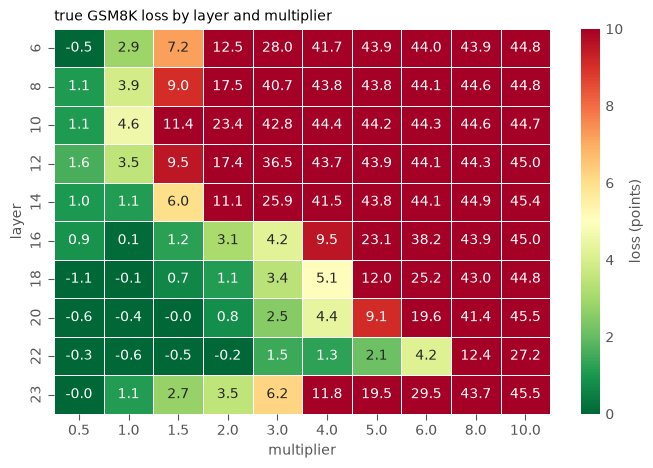

In [6]:
truth = pd.DataFrame(replay.truth(grid))

apply_plot_style()
plot_metric_heatmap(
    100 * truth.pivot(index="layer", columns="multiplier", values="loss"),
    title="true GSM8K loss by layer and multiplier",
    xlabel="multiplier",
    ylabel="layer",
    fmt=".1f",
    cmap="RdYlGn_r",
    vmin=0,
    vmax=200 * MARGIN,
    cbar_label="loss (points)",
)
plt.show()

The second heatmap shows the gain in points, on a color scale centered on zero. The gain grows with the multiplier over most of the grid and turns negative at the strongest settings of layers 18 and 20. In every layer the setting with the largest gain has a loss above the margin, which means that the margin limits the multiplier of every layer.

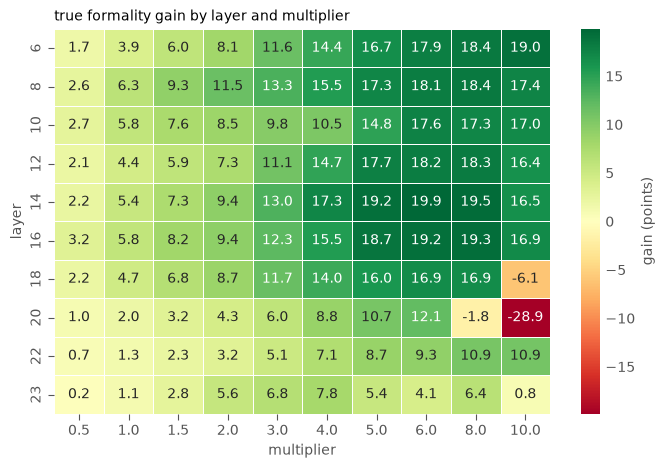

In [7]:
gain_limit = 100 * truth["gain"].max()
plot_metric_heatmap(
    100 * truth.pivot(index="layer", columns="multiplier", values="gain"),
    title="true formality gain by layer and multiplier",
    xlabel="multiplier",
    ylabel="layer",
    fmt=".1f",
    vmin=-gain_limit,
    vmax=gain_limit,
    cbar_label="gain (points)",
)
plt.show()

The table below lists the five settings with the largest gain among those whose loss is within the margin (both in points). These are the settings that a study should find.

In [8]:
inside = truth[truth["loss"] <= MARGIN]
(100 * inside.nlargest(5, "gain").set_index(["layer", "multiplier"])).round(1)

,,loss,gain
layer,multiplier,,
16,3.0,4.2,12.3
18,3.0,3.4,11.7
16,2.0,3.1,9.4
22,6.0,4.2,9.3
20,4.0,4.4,8.8


## Study definition

A study splits the items of each benchmark into a search pool and a held-out pool. Every decision during the search uses search items, and the held-out items are read once, by certification. The recorded grid has scores for the search items of the split at the time of recording only. The `build_world` function therefore draws both pools of each benchmark with replacement from the recorded items (3,792 search and 5,000 held-out GSM8K items, 1,500 search and 600 held-out prompts). Each drawn item gets a new id, and its score under a setting is the recorded score of the item it was drawn from. Both pools are then independent samples of a population whose means are the true values above.

The function returns the two benchmarks, their pools, a protocol, and a pipeline factory. Since the benchmarks read their scores from the grid and the factory steers nothing, the study runs without a model.

In [9]:
world = replay.build_world(grid, seed=SEED)

W1121 09:09:26.127000 3257016 torch/utils/cpp_extension.py:178] No CUDA runtime is found, using CUDA_HOME='/usr/local/cuda-12.9'


The search space maps a structure name to a `Template`. This study has one structure, i.e., the `CAA` entry of the grid with two free arguments. The `layer_id` argument is an unordered `Choice`, which makes it a proposer axis (a candidate is one layer). The `multiplier` argument is an ordered `Choice`, which makes it the solved axis. For each candidate, the evaluator finds the multiplier with the best behavior among those inside the margin.

Note that the vector is not fitted in the replay. The entry identifies each recipe, and the replay benchmarks return the scores recorded for the layer and the multiplier of the recipe.

In [10]:
space = {
    "caa": Template((
        entry(
            CAA,
            data=PAIRS,
            train_spec={"method": "mean_diff", "accumulate": "all"},
            layer_id=Choice(LAYERS),
            multiplier=Choice(MULTIPLIERS, ordered=True),
        ),
    )),
}

The `Study` dataclass combines the protocol, the space, the objective, the constraint with its margin, and the pools. The `monotone` argument lists the solved axes along which the capability loss is assumed not to fall as the position rises. For such an axis, the evaluator searches the multipliers by bisection, as the Search section describes. The `round_candidates` field of `Settings` is the number of candidates per round. With `ROUND_CANDIDATES` set to 5, the ten layers span two rounds.

In [11]:
study = Study(
    name="formality-gsm8k-replay",
    protocol=world.protocol,
    space=space,
    objective=world.formality,
    constraints=(Constraint(world.gsm8k, margin=MARGIN),),
    pools=world.pools,
    seed=SEED,
    settings=Settings(round_candidates=ROUND_CANDIDATES),
    monotone=frozenset({"caa.multiplier"}),
)

## Baseline and block sizes

The `start` method of `StudySession` validates the study and checks that its pools are large enough for its margin. It then measures the unsteered baseline on every search and held-out item. The search items are measured twice in different batch orders, and the mean absolute difference between the two measurements is the noise floor of the benchmark.

A study is certified once per store, and a replay generates nothing. We therefore remove `SAVE_DIR` and start from an empty store on every run.

In [12]:
shutil.rmtree(SAVE_DIR, ignore_errors=True)
store = Store.open(SAVE_DIR / "store")

with StudySession(study, store=store, factory=world.factory) as session:
    session.start()

The table shows the pools and the baseline of each benchmark.

In [13]:
baseline_rows = []
for benchmark in study.benchmarks:
    search_items = evidence.usable(study, store, benchmark, "search")
    scores = store.get_evidence(
        study.protocol.id,
        evidence.baseline_resolved_id(study, store, benchmark),
        benchmark.id,
        search_items,
        replicate=0,
    )
    baseline_rows.append({
        "benchmark": benchmark.name,
        "search items": len(search_items),
        "held-out items": len(evidence.usable(study, store, benchmark, "held_out")),
        "baseline mean": sum(row.value for row in scores.values()) / len(scores),
        "noise floor": evidence.noise_floor(study, store, benchmark),
    })
pd.DataFrame(baseline_rows)

,benchmark,search items,held-out items,baseline mean,noise floor
0,behavior,1500,600,0.789012,0.000005
1,capability,3792,5000,0.465717,0.000264


Each round draws two blocks of search items per benchmark, i.e., a ladder block on which the multipliers are screened and a fresh block on which they are judged. The study sizes the blocks of a constraint from its baseline. The design variance is the variance of the baseline's scores, with a minimum of `margin * (1 - margin)`. The fresh block has the number of items at which a loss estimate with this variance has a standard error of about a third of the margin, and the ladder block is a quarter of the fresh block. A confirmation reads the fresh block in three looks.

The guard band is the distance by which a loss estimate must lie inside the margin for the point to pass the held-out test with probability `power` (0.80 by default). The value below is the design value, i.e., the band at the design variance and the full fresh block.

In [14]:
gsm8k = world.gsm8k
variance = evidence.design_variance(study, store, gsm8k)
ladder_block, fresh_block = evidence.block_sizes(study, store, gsm8k)
band = guard_band(
    math.sqrt(variance / fresh_block),
    math.sqrt(variance / len(evidence.usable(study, store, gsm8k, "held_out"))),
    alpha=study.settings.alpha,
    power=study.settings.power,
    benchmarks=len(study.constraints),
)

pd.Series(
    {
        "design variance": round(variance, 3),
        "ladder block (items)": ladder_block,
        "fresh block (items)": fresh_block,
        "looks (items)": look_sizes(fresh_block),
        "guard band (points)": round(100 * band, 2),
        "margin minus band (points)": round(100 * (MARGIN - band), 2),
    },
    name=gsm8k.name,
).to_frame()

,capability
design variance,0.249
ladder block (items),250
fresh block (items),1000
looks (items),"(64, 256, 1000)"
guard band (points),2.61
margin minus band (points),2.39


## Search

The `run_study` function asks a proposer for candidates and evaluates them through a `StudySession`. The `GridProposer` proposes every layer once.

For each layer, a quick look at a few multipliers on a few items rejects a candidate that shows no gain, or whose loss is significantly over the margin at the smallest multiplier. Calibration then gives each multiplier, from the smallest up, a first look on the start of the ladder block, and it stops at the first multiplier whose loss is clearly over the margin. The behavior of the remaining multipliers is measured on the objective's ladder block. Among the multipliers up to the one with the best lower bound of its gain, a bisection then finds the largest multiplier that passes the looks of a confirmation on the fresh block (up to three looks). The multipliers up to that one are confirmed in the order of their gain bound, and the first one confirmed is the operating point. This means that a candidate is rejected only when no multiplier passes a confirmation or none is within the cost and degeneracy limits.

In [15]:
archive = run_study(
    study,
    GridProposer(study),
    store=store,
    factory=world.factory,
)

The archive contains the latest result of every candidate. An accepted result has an operating point, i.e., the confirmed multiplier with the loss and the gain estimated on items of the fresh blocks. Its fitness is the one-sided lower bound of the gain. The table adds the true loss and gain of each operating point from the grid, and the number of generations that the candidate would cost on the model. Losses, gains, and the fitness are in points.

In [16]:
true_values = truth.rename(columns={"loss": "true loss", "gain": "true gain"})

result_rows = []
for result in archive.results():
    point = result.operating
    result_rows.append({
        "layer": archive.candidate(result.candidate_id).values["caa.layer_id"],
        "status": result.status,
        "reason": result.reason,
        "multiplier": point.position["caa.multiplier"] if point else None,
        "loss": point.loss(gsm8k.name) if point else None,
        "gain": point.gain if point else None,
        "fitness": result.fitness,
        "generations": sum(version.generations for version in archive.versions(result.candidate_id)),
    })
results = pd.DataFrame(result_rows).astype({"multiplier": float, "loss": float, "gain": float})
results = results.merge(true_values, on=["layer", "multiplier"], how="left")

point_columns = ["loss", "true loss", "gain", "true gain", "fitness"]
results[point_columns] = 100 * results[point_columns]
results[["layer", "status", "reason", "multiplier", *point_columns, "generations"]].round(2)

,layer,status,reason,multiplier,loss,true loss,gain,true gain,fitness,generations
0,6,accepted,None,0.5,-4.66,-0.50,1.82,1.72,0.78,3945
1,8,accepted,None,0.5,0.62,1.05,1.75,2.58,0.92,3459
2,10,accepted,None,0.5,1.01,1.05,2.24,2.67,1.35,3833
3,12,accepted,None,0.5,2.30,1.61,1.66,2.14,0.59,3088
4,14,accepted,None,1.0,1.13,1.11,4.29,5.36,3.53,3345
5,16,accepted,None,1.5,0.89,1.24,7.03,8.20,6.01,4223
6,18,accepted,None,2.0,0.89,1.11,7.08,8.67,6.09,5575
7,20,accepted,None,3.0,-0.70,2.51,5.77,5.98,4.77,4084
8,22,accepted,None,1.0,-4.30,-0.58,1.30,1.34,0.36,1440
9,23,accepted,None,1.5,2.20,2.74,2.16,2.76,0.89,3312


### Ladder of one candidate

The ladder of the candidate with the highest fitness shows how its multiplier is chosen. The points are the loss estimates on the first look of the ladder block (the first of the looks in the table above) with one standard error, and the solid line is the true loss. The horizontal lines mark the margin and the margin minus the guard band, and the vertical line marks the confirmed multiplier. Note that the first-look estimates are noisy since they use few items. They only prune the multipliers that are clearly over the margin, and the confirmed multiplier can have an estimate above the margin.

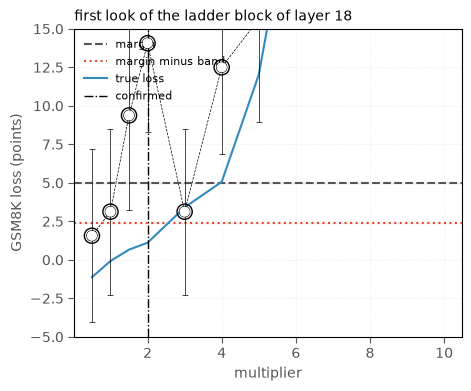

In [17]:
best = archive.best()
best_layer = archive.candidate(best.candidate_id).values["caa.layer_id"]

ladder = pd.DataFrame([
    {
        "multiplier": point.position["caa.multiplier"],
        "loss_mean": -100 * point.capability[gsm8k.name].mean,
        "loss_std": 100 * point.capability[gsm8k.name].se(),
    }
    for point in best.ladder
])
limits = [
    ("margin", pd.DataFrame({"loss_mean": [100 * MARGIN], "loss_std": [0.0]})),
    ("margin minus band", pd.DataFrame({"loss_mean": [100 * (MARGIN - band)], "loss_std": [0.0]})),
]
true_curve = truth[truth["layer"] == best_layer].sort_values("multiplier")

ax = plot_sensitivity(
    ladder,
    metric="loss",
    sweep_col="multiplier",
    compare_to_pipelines=limits,
    metric_label="GSM8K loss (points)",
    sweep_label="multiplier",
    title=f"first look of the ladder block of layer {best_layer}",
    ylim=(-100 * MARGIN, 300 * MARGIN),
)
ax.plot(
    true_curve["multiplier"],
    100 * true_curve["loss"],
    color="C0",
    label="true loss",
)
ax.axvline(
    best.operating.position["caa.multiplier"],
    color="black",
    linestyle="-.",
    linewidth=1,
    label="confirmed",
)
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.show()

### Re-scoring

At the end of each round the session draws new blocks and measures the accepted results with the highest fitness on the new fresh blocks. Each re-score appends a version of the result, whose tables use the fresh blocks of every round. The best results are selected on their estimates, and the added items correct an estimate that was favorable by chance. The table lists the versions of the candidate above, with the loss, the gain, and the fitness in points.

In [18]:
versions = pd.DataFrame([
    {
        "version": result.version,
        "multiplier": result.operating.position["caa.multiplier"],
        "GSM8K items": result.operating.capability[gsm8k.name].n,
        "loss": 100 * result.operating.loss(gsm8k.name),
        "gain": 100 * result.operating.gain,
        "fitness": 100 * result.fitness,
    }
    for result in archive.versions(best.candidate_id)
])
versions.round(2)

,version,multiplier,GSM8K items,loss,gain,fitness
0,1,2.0,1000,1.70,6.87,5.61
1,2,2.0,1690,0.89,7.08,6.09


## Certification

The `certify` function first selects the finalists among the accepted results with a fitness of at least `min_gain`. The level of a point is its estimated loss as a share of the margin. At each of five evenly spaced levels (the `finalists` field of `Settings`), the result with the highest fitness among those at or below the level becomes a finalist. Each finalist is measured on search items it has not been evaluated on, and the finalists are ordered by the resulting level, lowest first. The order is recorded before any held-out item is read.

Each finalist is then evaluated on the whole held-out pool, in order. A finalist is certified when the one-sided lower bound of its accuracy difference to the baseline is above `-margin`, and testing stops at the first finalist that fails. Since the order is fixed before the held-out items are read, each test uses the full error rate `alpha`. The procedure is designed to certify a point whose true loss exceeds the margin with a probability of at most `alpha` (0.05 by default). The cell returns the number of certified finalists and the index of the first finalist that failed (`None` when every finalist passed).

In [19]:
with StudySession(study, store=store, factory=world.factory) as session:
    session.start()
    certification = certify(session, bundle_dir=SAVE_DIR / "bundles")

len(certification.certified), certification.failed_at

(2, None)

The table lists the certified points. The held-out loss and the held-out gain are the estimates on the held-out pools. The loss bound is the one-sided upper bound of the loss at `alpha`, which is below the margin for a certified point. The last two columns are the true loss and gain from the grid. All values except the level are in points.

In [20]:
certified = pd.DataFrame(
    [
        {
            "layer": certificate["values"]["caa.layer_id"],
            "multiplier": certificate["position"]["caa.multiplier"],
            "level": certificate["finalists"][certificate["index"]]["level"],
            "held-out loss": -certificate["constraints"][gsm8k.name]["delta"],
            "loss bound": -certificate["constraints"][gsm8k.name]["lower_bound"],
            "held-out gain": certificate["behavior"]["gain"],
        }
        for certificate in certification.certificates.values()
    ],
    columns=["layer", "multiplier", "level", "held-out loss", "loss bound", "held-out gain"],
).astype({"layer": int, "multiplier": float})
certified = certified.merge(true_values, on=["layer", "multiplier"], how="left")

held_out_columns = ["held-out loss", "loss bound", "held-out gain", "true loss", "true gain"]
certified[held_out_columns] = 100 * certified[held_out_columns]
certified.round(2)

,layer,multiplier,level,held-out loss,loss bound,held-out gain,true loss,true gain
0,18,2.0,0.04,0.32,1.53,8.51,1.11,8.67
1,20,3.0,0.08,1.32,2.58,5.42,2.51,5.98


Note that on a loaded model, `certify` also writes each certified point to `bundle_dir` as a frozen `.spipe` bundle whose lock contains the certificate. The replay has no pipeline to save, and the files it writes there are placeholders.

## Study points on the grid

The last figure places the points of the study among the recorded settings, by true loss and true gain. It shows the settings with a true loss of up to three times the margin, and the dashed line is the margin. A certified point is also an accepted one and is drawn as certified.

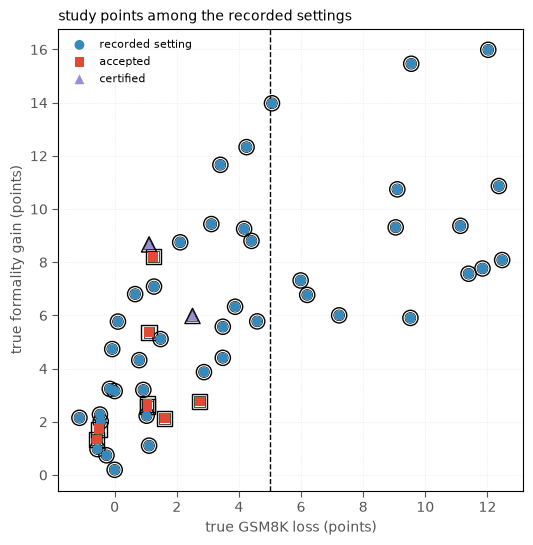

In [21]:
accepted = results.loc[results["status"] == "accepted", ["layer", "multiplier"]].assign(status="accepted")
selected = pd.concat([accepted, certified[["layer", "multiplier"]].assign(status="certified")])
selected = selected.drop_duplicates(["layer", "multiplier"], keep="last")
settings = truth.merge(selected, on=["layer", "multiplier"], how="left")
settings = settings.fillna({"status": "recorded setting"})
settings = settings[settings["loss"] <= 3 * MARGIN]

ax = plot_tradeoff_scatter(
    settings.assign(loss_mean=100 * settings["loss"], gain_mean=100 * settings["gain"]),
    x_metric="loss",
    y_metric="gain",
    group_col="status",
    group_order=["recorded setting", "accepted", "certified"],
    title="study points among the recorded settings",
    xlabel="true GSM8K loss (points)",
    ylabel="true formality gain (points)",
)
ax.axvline(
    100 * MARGIN,
    color="black",
    linestyle="--",
    linewidth=1,
)
plt.show()

## Repeated replays and studies on the model

The notebook shows one replay. The `run` command of `scripts/replay.py` repeats the replay over many seeds, which measures how often a study certifies a point whose true loss exceeds the margin.

The same `Study` runs on the model once the replay benchmarks and factory are replaced. The capability benchmark is then an `InspectBenchmark` on the task in `scripts/gsm8k_all.py`, and the objective is the benchmark defined in `scripts/formality.py`. The pools come from `split_items`. Without a `factory` argument, the session builds a `PipelineFactory` for the study's protocol, which fits the vector and steers the model.

The script `scripts/live_search.py` runs such a study over a larger space (a system prompt, the `CAA` vector, and both together). It compares a random proposer with `run_openevolve` (in which a language model proposes the candidates) at the same generation budget. A third arm runs `run_openevolve` on a study that chooses and judges its points on the same 100 GSM8K items.

## Takeaways

This notebook replayed a study that searches the layer and the multiplier of a `CAA` vector for formality under a GSM8K accuracy constraint. The multipliers of each layer were screened on a ladder block, and a bisection with the looks of a confirmation on a fresh block chose the operating point. The best results were re-scored on new items, and the finalists were certified on held-out items. Since the scores come from a recorded grid, each decision could be compared with the true loss and gain of the setting.